In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\jaysu\Downloads\profit-analysis_project\Profit-Analysis_Dataset.csv")

In [3]:
df.head(5)

,RD_Spend,Administration,Marketing_Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [27]:
df.shape

(50, 5)

In [28]:
df.columns

Index(['RD_Spend', 'Administration', 'Marketing_Spend', 'State', 'Profit'], dtype='object')

In [29]:
df.info

<bound method DataFrame.info of      RD_Spend  Administration  Marketing_Spend       State     Profit
0   165349.20       136897.80        471784.10    New York  192261.83
1   162597.70       151377.59        443898.53  California  191792.06
2   153441.51       101145.55        407934.54     Florida  191050.39
3   144372.41       118671.85        383199.62    New York  182901.99
4   142107.34        91391.77        366168.42     Florida  166187.94
5   131876.90        99814.71        362861.36    New York  156991.12
6   134615.46       147198.87        127716.82  California  156122.51
7   130298.13       145530.06        323876.68     Florida  155752.60
8   120542.52       148718.95        311613.29    New York  152211.77
9   123334.88       108679.17        304981.62  California  149759.96
10  101913.08       110594.11        229160.95     Florida  146121.95
11  100671.96        91790.61        249744.55  California  144259.40
12   93863.75       127320.38        249839.44     Florida

In [30]:
df.isnull().sum()

RD_Spend           0
Administration     0
Marketing_Spend    0
State              0
Profit             0
dtype: int64

In [31]:
x = df[["RD_Spend","Administration","Marketing_Spend"]]

In [32]:
y = df['Profit']

In [33]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [34]:
model = LinearRegression()

In [45]:
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


**In a Jupyter environment, please rerun this cell to show the HTML representation or trust the notebook.
On GitHub, the HTML representation is unable to render, please try loading this page with nbviewer.org.**

In [36]:
y_pred = model.predict(x_test)

In [37]:
y_pred

array([126703.02716461,  84894.75081556,  98893.41815974,  46501.70815036,
       129128.39734381,  50992.69486261, 109016.5536578 , 100878.4641454 ,
        97700.59638629, 113106.15292226])

In [38]:
r2 = r2_score(y_test, y_pred)
r2= round(r2*100,2)
rmse = round( mean_squared_error(y_test, y_pred) ** 0.5,2)
print("R² Score:", r2, "%")
print("RMSE:", rmse)

R² Score: 90.01 %
RMSE: 8995.91


In [39]:
print("Intercept:", model.intercept_)

print("R&D coefficient:", model.coef_[0])
print("Administration coefficient:", model.coef_[1])
print("Marketing coefficient:", model.coef_[2])

Intercept: 54071.875745990896
R&D coefficient: 0.8037792756297519
Administration coefficient: -0.06792917400149993
Marketing coefficient: 0.031241545897732884


In [40]:
new_data = pd.DataFrame({
    "RD_Spend": [21892.92, 23940.93],
    "Administration": [81910.77, 96489.63],
    "Marketing_Spend": [164270.70, 137001.10]
})

predictions = model.predict(new_data)

print(predictions)

[71236.89079079 71040.76440737]


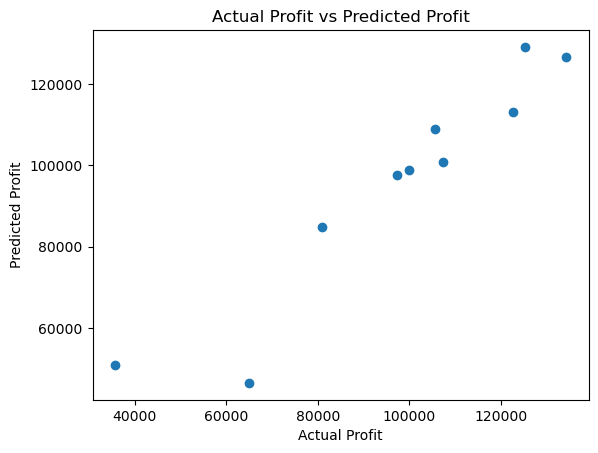

In [41]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual Profit vs Predicted Profit")

plt.show()

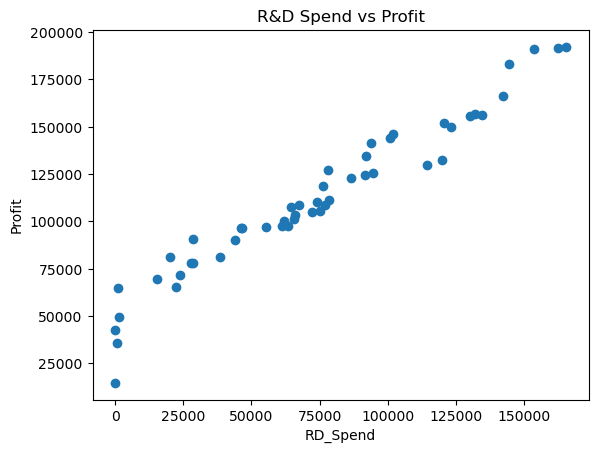

In [42]:
plt.scatter(df["RD_Spend"], df["Profit"])
plt.xlabel("RD_Spend")
plt.ylabel("Profit")
plt.title("R&D Spend vs Profit")
plt.show()

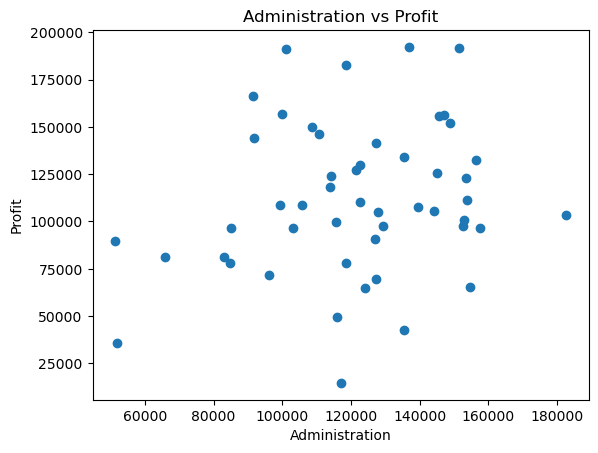

In [43]:
plt.scatter(df["Administration"], df["Profit"])
plt.xlabel("Administration")
plt.ylabel("Profit")
plt.title("Administration vs Profit")
plt.show()

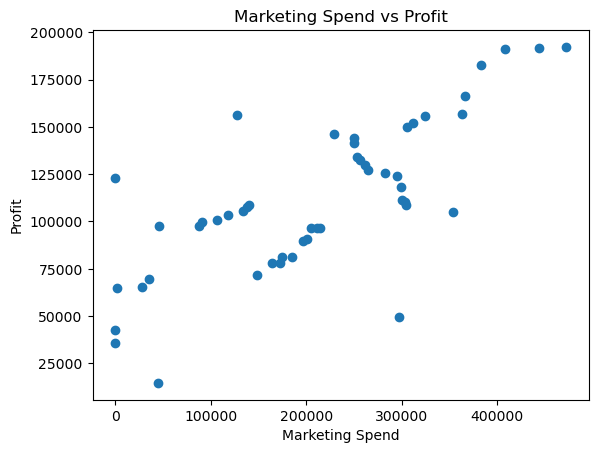

In [44]:
plt.scatter(df["Marketing_Spend"], df["Profit"])
plt.xlabel("Marketing Spend")
plt.ylabel("Profit")
plt.title("Marketing Spend vs Profit")
plt.show()